In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier

from sklearn.metrics import (accuracy_score,classification_report,confusion_matrix,roc_auc_score,roc_curve,mean_squared_error,mean_absolute_error,r2_score)

from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.inspection import permutation_importance

In [3]:
df = pd.read_csv("paytm_fraud_detection_dataset.csv")

In [4]:
df.shape

(70000, 27)

In [5]:
df.head(5)

,transaction_id,transaction_time,transaction_date,transaction_month,transaction_day,transaction_hour,is_weekend,amount,merchant_category,payment_method,...,failed_attempts,transaction_frequency_30d,avg_transaction_amount_30d,login_time_gap_hours,account_balance,beneficiary_count,kyc_verified,vpn_used,new_device_login,isFraud
0,TXN100000,15:46:46,2025-05-11,5,11,15,1,1642.44,Bills,Wallet,...,3,19,2606.76,11.43,64814.49,2,0,1,0,0
1,TXN100001,03:27:37,2024-01-24,1,24,3,0,4480.45,Recharge,UPI,...,1,21,4033.33,6.42,44305.18,28,1,0,1,0
2,TXN100002,16:42:30,2025-04-02,4,2,16,0,12741.05,Food,Wallet,...,0,3,5248.69,14.50,4332.01,26,0,1,0,0
3,TXN100003,00:54:28,2024-03-13,3,13,0,0,359.72,Shopping,Bank Transfer,...,1,7,5233.82,18.72,24478.91,2,0,1,0,0
4,TXN100004,18:46:59,2025-03-04,3,4,18,0,1937.80,Entertainment,Bank Transfer,...,0,4,5322.64,13.31,52108.79,16,0,1,0,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 27 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   transaction_id               70000 non-null  object 
 1   transaction_time             70000 non-null  object 
 2   transaction_date             70000 non-null  object 
 3   transaction_month            70000 non-null  int64  
 4   transaction_day              70000 non-null  int64  
 5   transaction_hour             70000 non-null  int64  
 6   is_weekend                   70000 non-null  int64  
 7   amount                       70000 non-null  float64
 8   merchant_category            70000 non-null  object 
 9   payment_method               70000 non-null  object 
 10  sender_account_age_months    70000 non-null  int64  
 11  receiver_account_age_months  70000 non-null  int64  
 12  device_id                    70000 non-null  object 
 13  device_type     

In [7]:
df.describe()

,transaction_month,transaction_day,transaction_hour,is_weekend,amount,sender_account_age_months,receiver_account_age_months,failed_attempts,transaction_frequency_30d,avg_transaction_amount_30d,login_time_gap_hours,account_balance,beneficiary_count,kyc_verified,vpn_used,new_device_login,isFraud
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,65800.000000,65800.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,6.511086,15.753971,11.495271,0.283914,3507.765994,60.059086,59.907371,0.996500,17.495229,4000.332162,12.101298,55273.466688,20.084671,0.500886,0.503643,0.503057,0.258943
std,3.447631,8.773911,6.914695,0.450899,3510.725636,34.330269,34.328393,1.001436,9.810247,1498.504453,5.791882,24560.105402,11.249418,0.500003,0.499990,0.499994,0.438057
min,1.000000,1.000000,0.000000,0.000000,0.070000,1.000000,1.000000,0.000000,1.000000,-2620.830000,0.000000,13.290000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,4.000000,8.000000,6.000000,0.000000,1002.225000,30.000000,30.000000,0.000000,9.000000,2986.065000,7.930000,38212.910000,10.000000,0.000000,0.000000,0.000000,0.000000
50%,7.000000,16.000000,11.000000,0.000000,2424.950000,60.000000,60.000000,1.000000,18.000000,3996.030000,12.020000,54981.670000,20.000000,1.000000,1.000000,1.000000,0.000000
75%,10.000000,23.000000,17.000000,1.000000,4875.982500,90.000000,90.000000,2.000000,26.000000,5018.705000,16.050000,71902.097500,30.000000,1.000000,1.000000,1.000000,1.000000
max,12.000000,31.000000,23.000000,1.000000,35841.110000,119.000000,119.000000,7.000000,34.000000,10718.630000,34.680000,162471.440000,39.000000,1.000000,1.000000,1.000000,1.000000


In [8]:
df.isnull().sum()

transaction_id                    0
transaction_time                  0
transaction_date                  0
transaction_month                 0
transaction_day                   0
transaction_hour                  0
is_weekend                        0
amount                            0
merchant_category                 0
payment_method                    0
sender_account_age_months         0
receiver_account_age_months       0
device_id                         0
device_type                    4200
ip_address                     4200
city                           4200
state                          4200
failed_attempts                   0
transaction_frequency_30d         0
avg_transaction_amount_30d     4200
login_time_gap_hours           4200
account_balance                   0
beneficiary_count                 0
kyc_verified                      0
vpn_used                          0
new_device_login                  0
isFraud                           0
dtype: int64

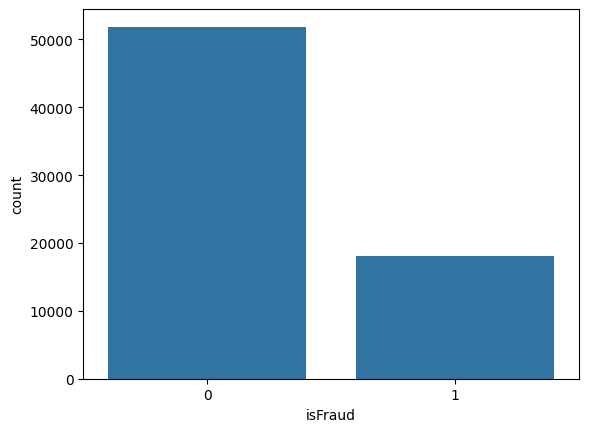

In [7]:
sns.countplot(x='isFraud', data=df)
plt.show()

In [8]:
num_cols = df.select_dtypes(include=np.number).columns
num_cols

Index(['transaction_month', 'transaction_day', 'transaction_hour',
       'is_weekend', 'amount', 'sender_account_age_months',
       'receiver_account_age_months', 'failed_attempts',
       'transaction_frequency_30d', 'avg_transaction_amount_30d',
       'login_time_gap_hours', 'account_balance', 'beneficiary_count',
       'kyc_verified', 'vpn_used', 'new_device_login', 'isFraud'],
      dtype='object')

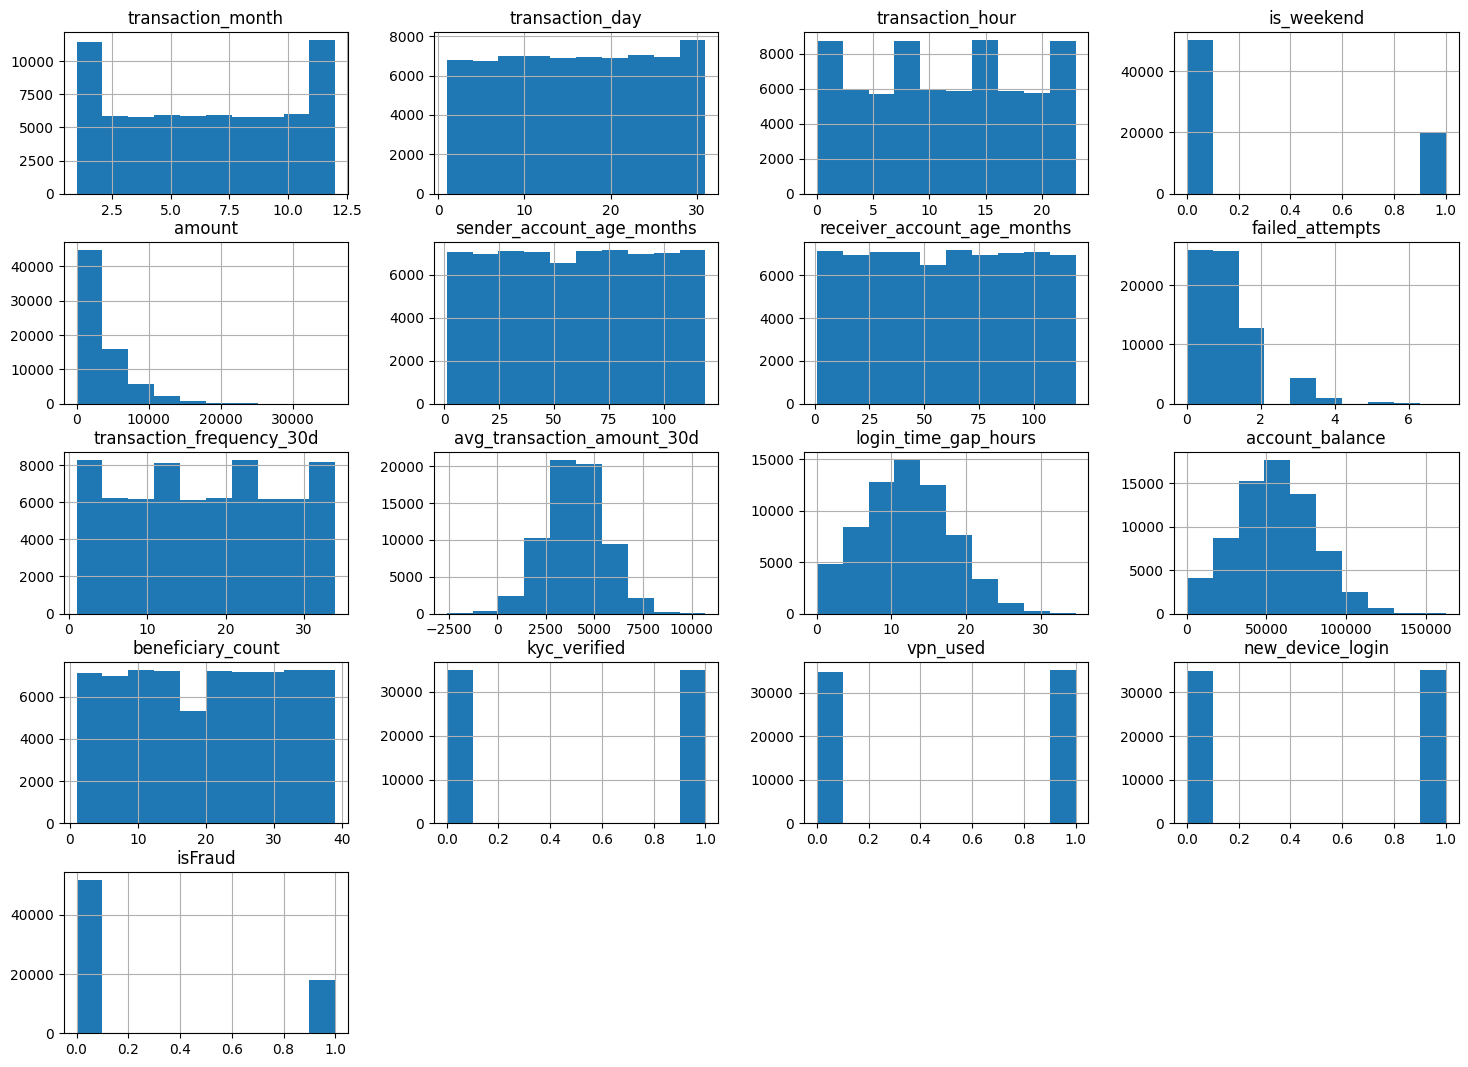

In [9]:
df[num_cols].hist(figsize=(18,13))
plt.show()

In [9]:
df["device_type"] = df["device_type"].fillna("Unknown_Device") 

df["ip_address"] = df["ip_address"].fillna("Unknown_IP")

df["city"] = df["city"].fillna("Unknown_City")

df["state"] = df["state"].fillna("Unknown_State")


In [10]:
df["avg_transaction_amount_30d"] = (
    df.groupby(
        ["transaction_frequency_30d", "payment_method"],
        observed=True
    )["avg_transaction_amount_30d"]
    .transform(lambda x: x.fillna(x.median()))
)


In [11]:
df["login_time_gap_hours"] = df["login_time_gap_hours"].fillna(
    df.groupby(["device_id", "ip_address"])["login_time_gap_hours"].transform("median")
)

df["login_time_gap_hours"] = df["login_time_gap_hours"].fillna(
    df.groupby("device_type")["login_time_gap_hours"].transform("median")
)

df["login_time_gap_hours"] = df["login_time_gap_hours"].fillna(
    df.groupby("transaction_frequency_30d")["login_time_gap_hours"].transform("median")
)
df["login_time_gap_hours"] = df["login_time_gap_hours"].fillna(
    df["transaction_frequency_30d"].median()
)

In [12]:
df.isnull().sum()

transaction_id                 0
transaction_time               0
transaction_date               0
transaction_month              0
transaction_day                0
transaction_hour               0
is_weekend                     0
amount                         0
merchant_category              0
payment_method                 0
sender_account_age_months      0
receiver_account_age_months    0
device_id                      0
device_type                    0
ip_address                     0
city                           0
state                          0
failed_attempts                0
transaction_frequency_30d      0
avg_transaction_amount_30d     0
login_time_gap_hours           0
account_balance                0
beneficiary_count              0
kyc_verified                   0
vpn_used                       0
new_device_login               0
isFraud                        0
dtype: int64

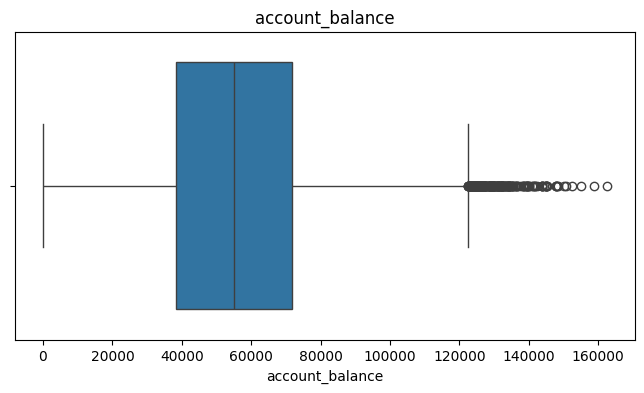

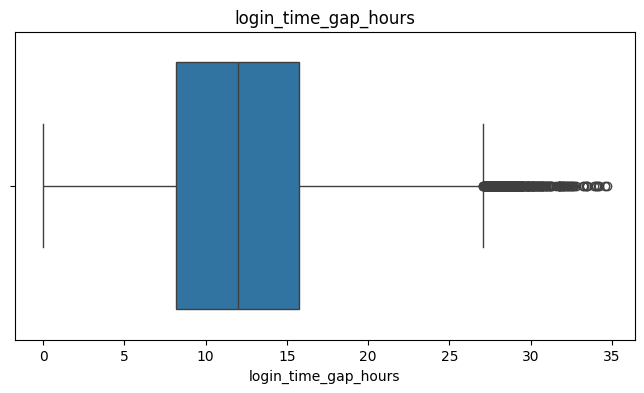

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
for col in [
    "account_balance",
    "login_time_gap_hours"
]:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

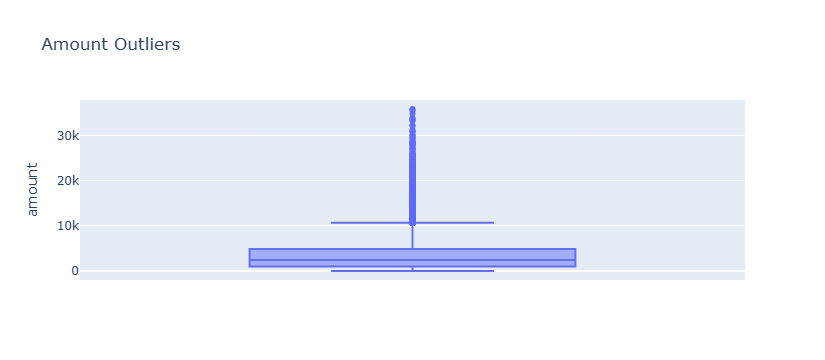

In [17]:
import plotly.express as px

fig = px.box(
    df,
    y="amount",
    points="outliers",
    title="Amount Outliers"
)

fig.show()

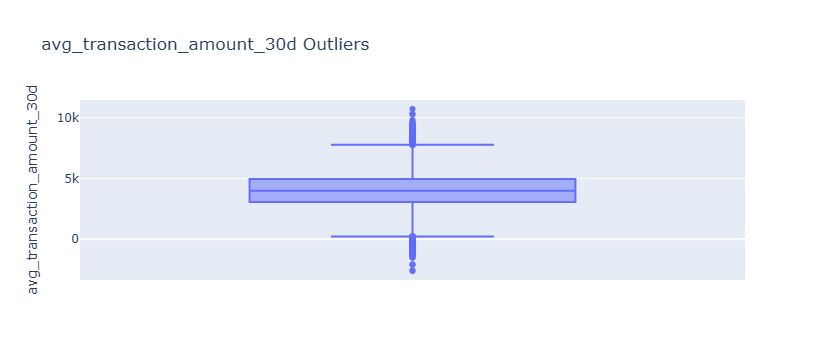

In [15]:
fig = px.box(
    df,
    y="avg_transaction_amount_30d",
    points="outliers",
    title="avg_transaction_amount_30d Outliers"
)

fig.show()

In [16]:
df

,transaction_id,transaction_time,transaction_date,transaction_month,transaction_day,transaction_hour,is_weekend,amount,merchant_category,payment_method,...,failed_attempts,transaction_frequency_30d,avg_transaction_amount_30d,login_time_gap_hours,account_balance,beneficiary_count,kyc_verified,vpn_used,new_device_login,isFraud
0,TXN100000,15:46:46,2025-05-11,5,11,15,1,1642.44,Bills,Wallet,...,3,19,2606.76,11.43,64814.49,2,0,1,0,0
1,TXN100001,03:27:37,2024-01-24,1,24,3,0,4480.45,Recharge,UPI,...,1,21,4033.33,6.42,44305.18,28,1,0,1,0
2,TXN100002,16:42:30,2025-04-02,4,2,16,0,12741.05,Food,Wallet,...,0,3,5248.69,14.50,4332.01,26,0,1,0,0
3,TXN100003,00:54:28,2024-03-13,3,13,0,0,359.72,Shopping,Bank Transfer,...,1,7,5233.82,18.72,24478.91,2,0,1,0,0
4,TXN100004,18:46:59,2025-03-04,3,4,18,0,1937.80,Entertainment,Bank Transfer,...,0,4,5322.64,13.31,52108.79,16,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,TXN169995,18:39:27,2024-01-17,1,17,18,0,6013.28,Gaming,Wallet,...,1,27,5935.24,6.36,83587.70,15,1,1,1,1
69996,TXN169996,01:36:48,2024-11-29,11,29,1,0,2231.58,Bills,QR Scan,...,1,31,5214.62,13.57,68374.17,16,0,0,0,1
69997,TXN169997,16:42:17,2024-05-27,5,27,16,0,9632.63,Shopping,UPI,...,1,32,3816.54,20.34,70058.45,34,0,1,0,1
69998,TXN169998,00:42:23,2025-11-17,11,17,0,0,587.00,Recharge,QR Scan,...,1,33,4741.03,10.71,27827.21,13,0,0,1,0


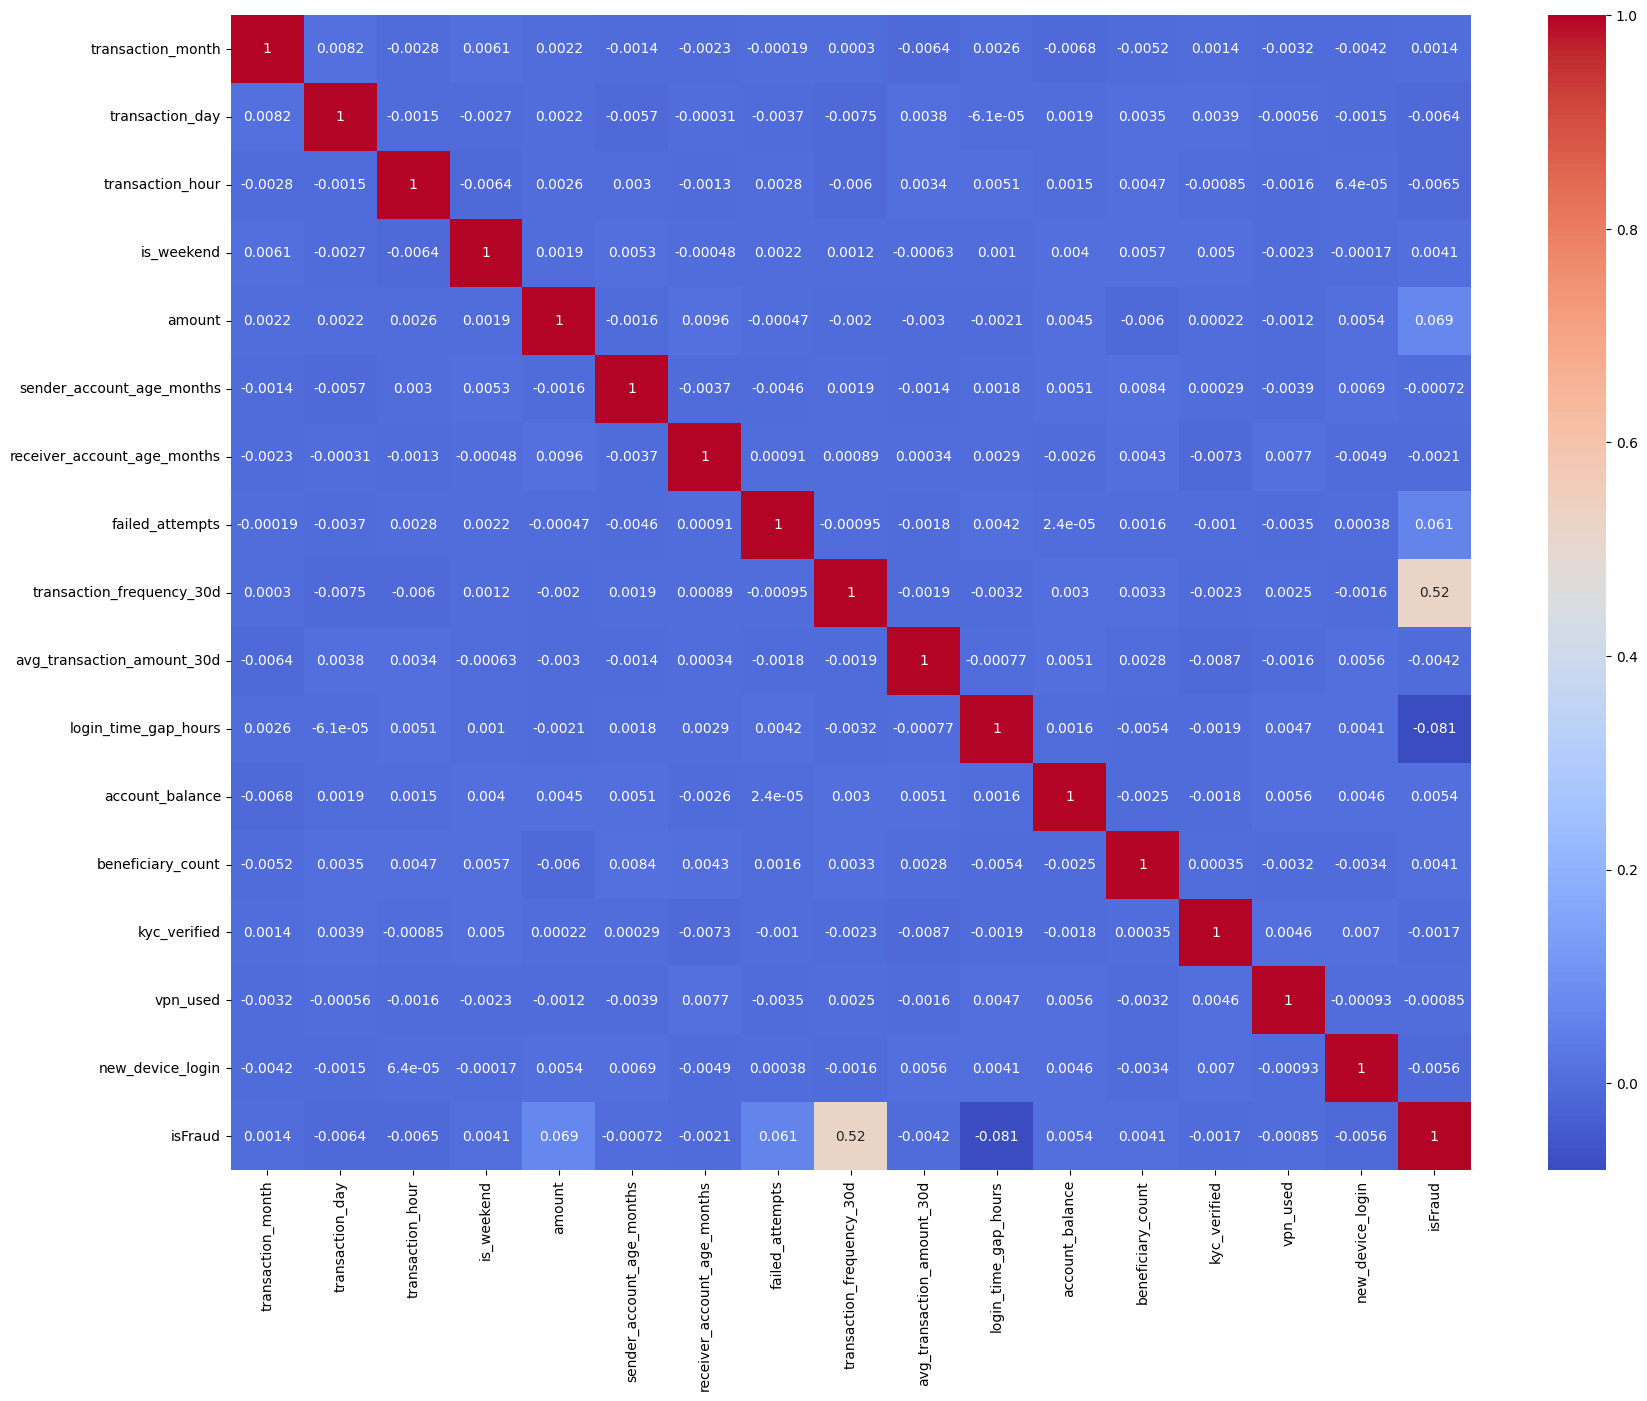

In [19]:
plt.figure(figsize=(20,15))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm')
plt.show()

In [18]:
df.drop(
    columns=[
        "transaction_id",
        "transaction_date",
        "transaction_time"
    ],
    inplace=True
)

In [20]:
df["ip_txn_count"] = (
    df.groupby("ip_address")["ip_address"]
      .transform("count")
)

In [21]:
df.drop(
    columns=["device_id", "ip_address"],
    inplace=True
)

In [23]:
from sklearn.preprocessing import LabelEncoder

categorical_cols = [
    "merchant_category",
    "payment_method",
    "device_type",
    "city",
    "state",
    "avg_transaction_amount_30d"
]

for col in categorical_cols:
    df[col] = LabelEncoder().fit_transform(df[col])

In [24]:
df.head(5)

,transaction_month,transaction_day,transaction_hour,is_weekend,amount,merchant_category,payment_method,sender_account_age_months,receiver_account_age_months,device_type,...,avg_transaction_amount_30d,login_time_gap_hours,account_balance,beneficiary_count,kyc_verified,vpn_used,new_device_login,isFraud,device_txn_count,ip_txn_count
0,5,11,15,1,1642.44,0,3,117,100,0,...,11213,11.43,64814.49,2,0,1,0,0,12,1
1,1,24,3,0,4480.45,7,2,33,76,1,...,31524,6.42,44305.18,28,1,0,1,0,3,1
2,4,2,16,0,12741.05,4,3,73,39,3,...,49059,14.50,4332.01,26,0,1,0,0,6,1
3,3,13,0,0,359.72,8,0,44,8,0,...,48895,18.72,24478.91,2,0,1,0,0,10,1
4,3,4,18,0,1937.80,3,0,48,15,2,...,49909,13.31,52108.79,16,0,1,0,0,11,1


In [25]:
X = df.drop('isFraud', axis=1)
y = df['isFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(X_train.shape)
print(X_test.shape)

(56000, 23)
(14000, 23)


In [26]:
"""Decision tree"""

'Decision tree'

In [27]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

dt_preds = dt.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, dt_preds))


Decision Tree Accuracy: 0.8261428571428572


In [ ]:
"""Random Forest"""

In [28]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    max_features='sqrt',
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [29]:
rf_preds = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_preds))


Random Forest Accuracy: 0.9002857142857142


              precision    recall  f1-score   support

           0       0.96      0.90      0.93     10375
           1       0.76      0.90      0.82      3625

    accuracy                           0.90     14000
   macro avg       0.86      0.90      0.88     14000
weighted avg       0.91      0.90      0.90     14000



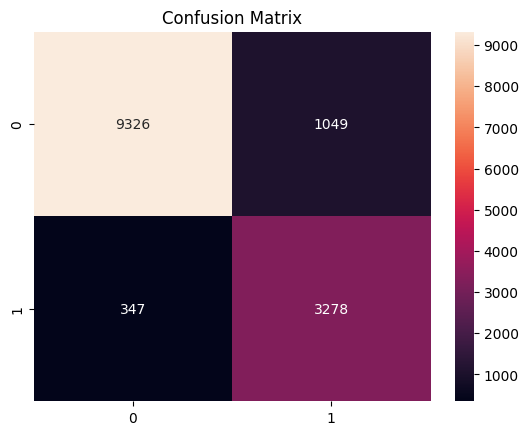

In [30]:
print(classification_report(y_test, rf_preds))

cm = confusion_matrix(y_test, rf_preds)

sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()


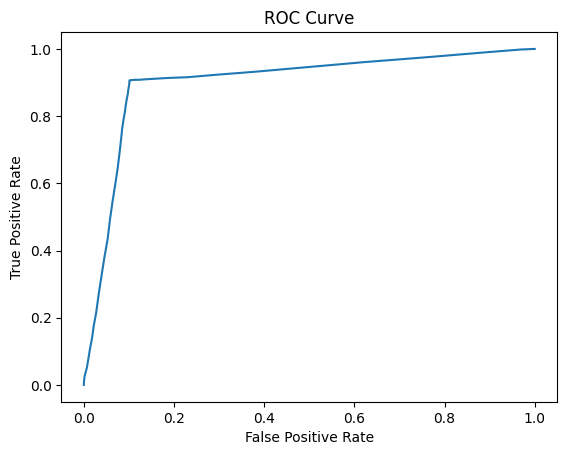

ROC AUC Score: 0.8998082791857083


In [31]:
rf_probs = rf.predict_proba(X_test)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, rf_probs)

plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

print("ROC AUC Score:", roc_auc_score(y_test, rf_probs))


In [32]:
print("OOB Score:", rf.oob_score_)

OOB Score: 0.8995892857142858


In [33]:
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)
importance_df


,Feature,Importance
13,transaction_frequency_30d,0.310239
21,txn_freq_group,0.183927
15,login_time_gap_hours,0.086890
4,amount,0.055265
12,failed_attempts,0.038480
16,account_balance,0.033667
14,avg_transaction_amount_30d,0.033570
8,receiver_account_age_months,0.030018
7,sender_account_age_months,0.028820
17,beneficiary_count,0.025186


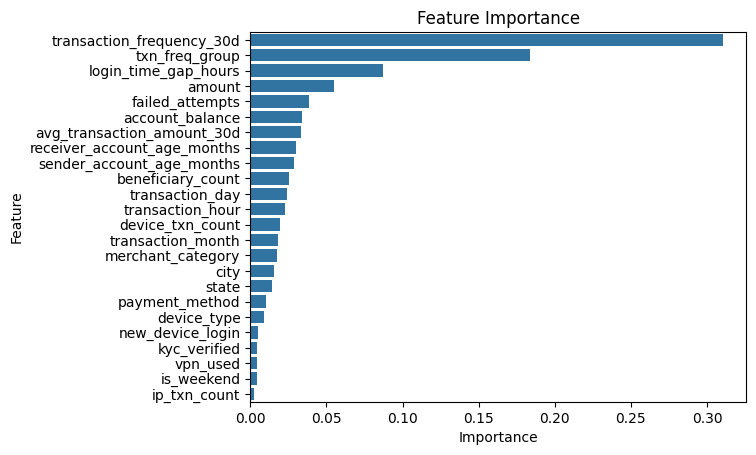

In [34]:
sns.barplot(
    x='Importance',
    y='Feature',
    data=importance_df
)

plt.title("Feature Importance")
plt.show()

In [ ]:
"""Ada boost model accuracy is 0.8768"""

In [ ]:
#XGBoost model

In [45]:
from xgboost import XGBClassifier

In [66]:
xgb_model = XGBClassifier(
    objective='binary:logistic',
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=1.0,
    eval_metric='logloss',
    random_state=42
)

In [67]:
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

In [68]:
print("accuracy:", accuracy_score(y_test, y_pred_xgb))

accuracy: 0.9


In [62]:
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.96      0.90      0.93     10375
           1       0.76      0.90      0.82      3625

    accuracy                           0.90     14000
   macro avg       0.86      0.90      0.88     14000
weighted avg       0.91      0.90      0.90     14000



In [55]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1, 0.2],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}
search = GridSearchCV(
    xgb_model,
    param_grid=param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1,
    verbose=2
)
search.fit(X_train, y_train)
print(search.best_params_)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}


In [56]:
best_model = search.best_estimator_


In [57]:
y_pred = best_model.predict(X_test)

In [53]:
print("Test Accuracy:", accuracy_score(y_test, y_pred))

Test Accuracy: 0.9


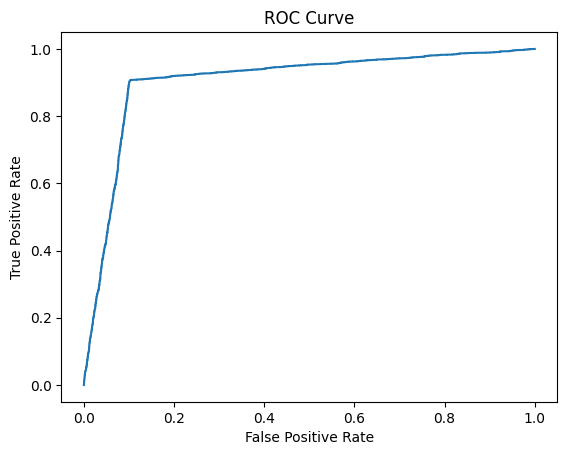

ROC AUC Score: 0.904394821769838


In [71]:
xgb_probs = xgb_model.predict_proba(X_test)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, xgb_probs)

plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

print("ROC AUC Score:", roc_auc_score(y_test, xgb_probs))
